In [1]:
#Xander Bergman
#11/2

#Imports
import numpy as np
import matplotlib.pyplot as plt
import glob
from scipy.special import factorial
from astropy.io import fits
from scipy.optimize import curve_fit
from astropy.modeling.functional_models import Gaussian2D, Ring2D 
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation, AltAz
import astropy.units as u

In [2]:
#Define functions for later
def count_conversion(measured_counts):
    """
    Converss raw CCD data into photon counts.
    """
    return (measured_counts/16) + 1

def load_files(file_list, step=1, print_header=False):
    """
    Loads a list of .fits files and aplies the count conversion
    so that the data can be read and displayed.
    """
    data_list = []
    file_num = 0
    for file in file_list:
        if file_num % step == 0:
            with fits.open(file) as foo:
                raw_data = foo[0].data
                header = foo[0].header
                real_data = count_conversion(raw_data)
                data_list.append(real_data)
        file_num += 1
    data_stack = np.array(data_list)

    print(f"Number of files found: {len(file_list)}")
    print(f"Shape of image stack: {data_stack.shape}")
    if print_header:
        print(f"Header: {header}")
    return data_stack

#Reduce data assumes count conversion already applied from load_files
def reduce_data(image, dark):
    """
    Adjusts loaded .fits files to account for systematic error.
    Adjusts for bias, darks, and flats.
    """
    image_biased = image - mean_bias
    image_darkened = image_biased - dark
    image_reduced = image_darkened / median_flat
    return image_reduced
    
def least_squares(x, y, y_uncert):
    """
    Calculates a linear least-squares fit given
    input parameters.
    """
    w = 1.0 / (y_uncert**2)
    N = len(x)

    sum_w = np.sum(w)
    sum_x = np.sum(w * x)
    sum_y = np.sum(w * y)
    sum_xx = np.sum(w * x**2)
    sum_xy = np.sum(w * x * y)

    delta = sum_w * sum_xx - (sum_x)**2
    y0 = (sum_xx * sum_y - sum_x * sum_xy) / delta
    slope_w = (sum_w * sum_xy - sum_x * sum_y) / delta

    y0_err = np.sqrt(sum_xx / delta)
    slope_err = np.sqrt(sum_w / delta)

    residuals = y - (y0 + slope_w * x)
    chi2_red = np.sum((residuals / y_uncert)**2) / (N - 2)
    return y0, y0_err, slope_w, slope_err, residuals, chi2_red
    
def psf(center, width_x, width_y, window, inner_rad=250):
    '''
    Evaluates a donut-shaped PSF -- created by combining a 2D ring with a 2D gaussian
    
    Input
    ---
    center: tuple 
        position centroid
    width_x: int
        integer number of pixels to define total width of 2D Gaussian in x-dir
    width_y: int
        integer number of pixels to define total width of 2D Gaussian in y-dir
    window: int
        window size
    inner_rad: int, optional
        value for number of pixels in inner radius. Default: 300
    
    Ouput
    ----
    xx: array
        positions in x around center with size 2x window
    yy: array
        positions in y around center with size 2x window
    normalized: array
        normalized Ring2D * Gauss2D point spread function
    '''

    loc=np.array(center)
    xx, yy = np.meshgrid(np.arange(loc[0]-window,loc[0]+window),
                     np.arange(loc[1]-window,loc[1]+window))
    gauss = Gaussian2D.evaluate(xx,yy,amplitude=1,theta=0,x_mean=loc[0], y_mean=loc[1], x_stddev=width_x, y_stddev=width_y)
    ring = Ring2D.evaluate(xx,yy,1,loc[0],loc[1],inner_rad,width=2*window)
    combined = ring * gauss
    normalized = combined / (np.sum(combined))
    return xx, yy, normalized 

def phot(data, centroid_x, centroid_y, width_x, width_y, window, inner_rad=250):
    """
    Evaluates the masked PSF model, extracts the corresponding data subwindow, 
    convolves them together, and returns the model, convolved array, and total flux.
    """
    xx, yy, model = psf((centroid_x, centroid_y), width_x, width_y, window, inner_rad)
    
    xmin, xmax = int(xx[0, 0]), int(xx[0, -1]) + 1
    ymin, ymax = int(yy[0, 0]), int(yy[-1, 0]) + 1
    
    data_window = data[ymin:ymax, xmin:xmax]
    model_sum_sq = np.sum(model**2)
    psf_convolve = data_window * model
    
    psf_flux = np.sum(psf_convolve) / model_sum_sq
    return model, psf_convolve, psf_flux

def plot_phot(image, cx, cy, window_size, model_grid, convolved_patch, target=""):
    """
    Plots a 2-panel comparison showing the original image data window, 
    and the final convolved result.
    """
    xmin, xmax = int(cx - window_size), int(cx + window_size)
    ymin, ymax = int(cy - window_size), int(cy + window_size)
    data_window = image[ymin:ymax, xmin:xmax]

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    im0 = axes[0].imshow(data_window, origin='lower', cmap='viridis', extent=[xmin, xmax, ymin, ymax])
    axes[0].set_title(f"{target} Original Data Window")
    axes[0].set_xlabel("X Pixel")
    axes[0].set_ylabel("Y Pixel")
    fig.colorbar(im0, ax=axes[0], label="Counts (ADU)")
    
    im1 = axes[1].imshow(convolved_patch, origin='lower', cmap='inferno', extent=[xmin, xmax, ymin, ymax])
    axes[1].set_title(f"Convolved Array ({target} Data × Model)")
    axes[1].set_xlabel("X Pixel")
    fig.colorbar(im1, ax=axes[1], label="Weighted Counts")

    plt.tight_layout()
    plt.savefig(f"{target}_plot.png")

def calc_mag(stellar_flux, exposure, sky_flux):
    """
    Calculates the instrumental magnitude of a star.
    """
    N_net = stellar_flux - sky_flux
    return -2.5 * np.log10(N_net / exposure)

def find_airmass(obs_time, target):
    """
    Uses astropy to find the coordinates of target star
    and calculates the airmass based on Missoula's location.
    """
    obs_time = Time(obs_time, scale='utc')
    observer_location = EarthLocation(
    lat= 46.872890 * u.deg,       
    lon=-114.004997 * u.deg,     
    height=978.0 * u.m      
)
    target = SkyCoord.from_name(target)
    altaz_frame = AltAz(obstime=obs_time, location=observer_location)
    target_altaz = target.transform_to(altaz_frame)
    airmass = target_altaz.secz
    return airmass

def correct_magnitude(inst_mag,target, time):
    """
    Adjusts instrumental magnetudes for the airmass
    and zeropoint to get true apparent magnitude.
    """
    airmass = find_airmass(time, target)
    real_mag = inst_mag + ZP + k * airmass
    print(f"Target: {target}")
    print(f"Airmass: {airmass}")
    print(f"Magnitude: {real_mag}")
    return real_mag, airmass

def calc_uncert(model, flux, mag, airmass, print_vals=False):
    """
    Calculates uncertainty using the lab handout formula: (1 / SNR) * mag.
    """
    n_eff = 1.0 / np.sum(model**2)
    
    variance = (gain * flux) + (n_eff * gain * sky_flux) + (n_eff * (read_noise**2))
    variance = np.maximum(variance, 1e-5)
    SNR = flux / np.sqrt(variance)
    inst_uncert = (1.0 / SNR) * mag
    air_uncert = airmass * k_uncert
    if print_vals:
        print(f"SNR: {SNR}")
        print(f"inst_uncert: {inst_uncert}")
        print(f"air_uncert: {air_uncert}")
    total_uncert = np.sqrt(inst_uncert**2 + ZP_uncert**2 + air_uncert**2)
    return total_uncert

In [3]:
#Grab list of file names
bias_images = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\BiasImages\*.fit"))
twilight_flats = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\TwilightFlats\*.fit"))
darks_5s = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\Darks5s\*.fit"))
darks_15s = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\Darks15s\*.fit"))
darks_30s = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\Darks30s\*.fit"))
darks_45s = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\Darks45s\*.fit"))
darks_60s = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\Darks60s\*.fit"))
darks_120s = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\Darks120s\*.fit"))

eps_del = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\EpsDel\*.fit"))
HD189658 = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\HD189658\*.fit"))
HD198727 = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\HD198727\*.fit"))
HD199280 = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\HD199280\*.fit"))

HD199280_2130 = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\HD199280pt2\*.fit"))
SA113267 = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\SA113267\*.fit"))
SA1111496 = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\SA1111496\*.fit"))

vega1 = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\Vega1\*.fit"))
vega2 = sorted(glob.glob(r"C:\Users\xande\ASTR362\Lab2\DonutData\Vega2\*.fit"))

Number of files found: 20
Shape of image stack: (20, 3522, 4656)
Medain of Mean Bias Image: 153.7


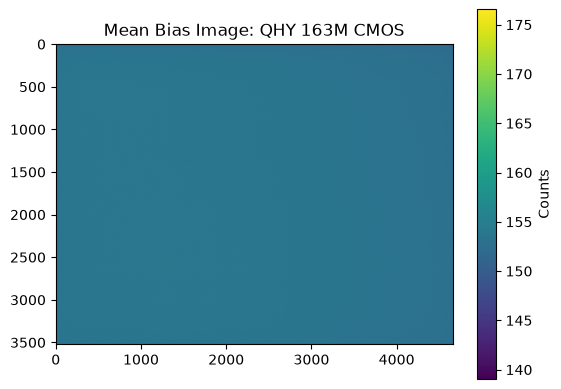

In [4]:
#Start Error Analysis Work, Same as Lab 1 
#Bias Images
bias_images = load_files(bias_images)

mean_bias = np.mean(bias_images, axis=0)
plt.imshow(mean_bias)
plt.colorbar(label="Counts")
plt.title("Mean Bias Image: QHY 163M CMOS")
plt.savefig("Mean_bias.png")

median_bias = np.median(mean_bias)
print(f"Medain of Mean Bias Image: {median_bias}")

Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 11
Shape of image stack: (11, 3522, 4656)


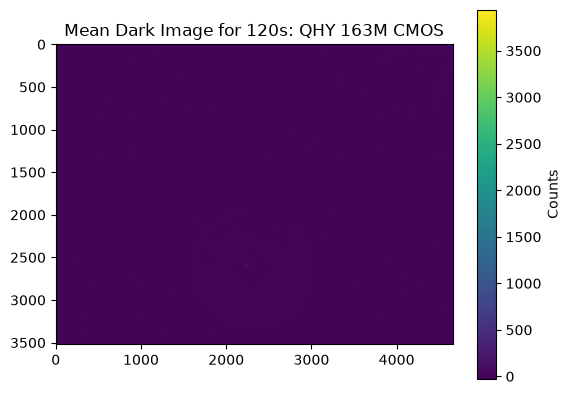

In [5]:
#Darks
darks_5s = load_files(darks_5s)
darks_5s -= mean_bias
mean_dark_5s = np.mean(darks_5s, axis=0)

darks_30s = load_files(darks_30s)
darks_30s -= mean_bias
mean_dark_30s = np.mean(darks_30s, axis=0)

darks_60s = load_files(darks_60s)
darks_60s -= mean_bias
mean_dark_60s = np.mean(darks_60s, axis=0)

darks_120s = load_files(darks_120s)
darks_120s -= mean_bias
mean_dark_120s = np.mean(darks_120s, axis=0)

plt.imshow(mean_dark_120s)
plt.colorbar(label="Counts")
plt.title("Mean Dark Image for 120s: QHY 163M CMOS")
plt.show()

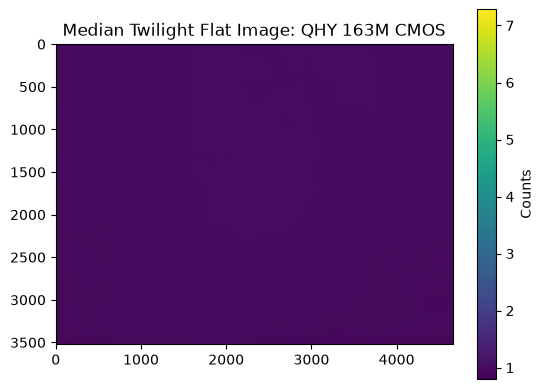

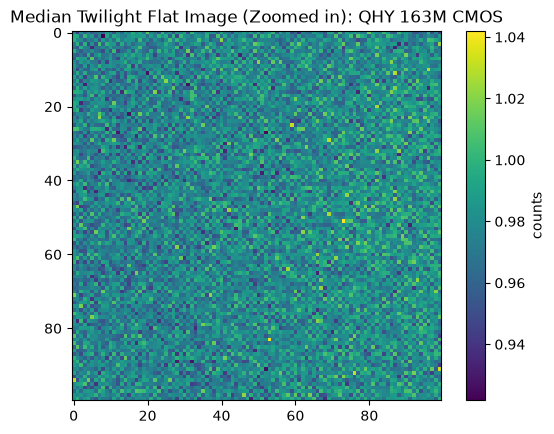

In [6]:
#Twilight Flats Need Their Own File loading Scheme
twilight_data_list = []
file_num = 0
for file in twilight_flats:
    if file_num % 4 == 0:
        with fits.open(file) as foo:
            raw_data = foo[0].data
            real_data = count_conversion(raw_data)
            bias_subtracted_flat = real_data - mean_bias
            median = np.median(bias_subtracted_flat)
            normalized_flat = bias_subtracted_flat / median
            twilight_data_list.append(normalized_flat)
            file_num += 1
    else:
        file_num += 1
twilight_stack = np.array(twilight_data_list)

median_flat = np.median(twilight_stack, axis=0)
plt.imshow(median_flat)
plt.colorbar(label="Counts")
plt.title("Median Twilight Flat Image: QHY 163M CMOS")
plt.show()

plt.imshow(median_flat[0:100,0:100])
plt.colorbar(label="counts")
plt.title("Median Twilight Flat Image (Zoomed in): QHY 163M CMOS")
plt.savefig("Median_flat.png")

Read noise: 2.121329462886427
Average Pixel Diff: -0.009406874998780372


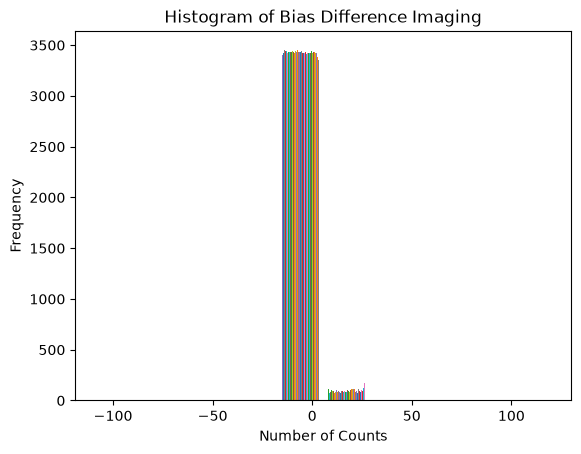

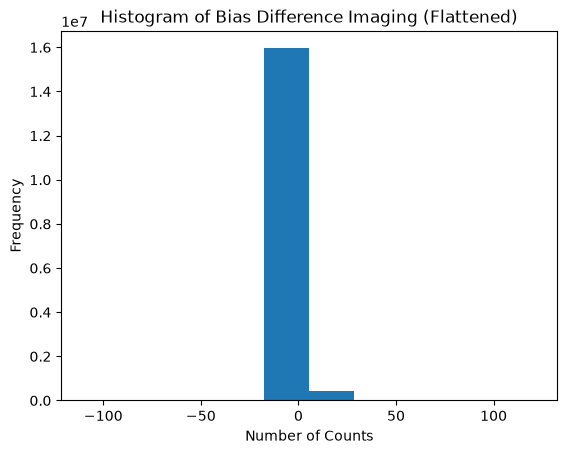

In [7]:
#Read Noise
#Calculate random error using difference imaging
sample_bias1 = bias_images[4]
sample_bias2 = bias_images[5]

bias_diff = sample_bias1 - sample_bias2
bias_diff_mean = np.mean(bias_diff)
bias_diff_stdev = np.std(bias_diff)
read_noise = bias_diff_stdev / np.sqrt(2)
print(f"Read noise: {read_noise}")
print(f"Average Pixel Diff: {bias_diff_mean}")

plt.hist(bias_diff)
plt.xlabel("Number of Counts")
plt.ylabel("Frequency")
plt.title("Histogram of Bias Difference Imaging")
plt.show()

bias_diff_flat = bias_diff.flatten()
plt.hist(bias_diff_flat)
plt.xlabel("Number of Counts")
plt.ylabel("Frequency")
plt.title("Histogram of Bias Difference Imaging (Flattened)")
plt.savefig("Bias_hist.png")

--- Least Squares Fit Results ---
Intercept (Read Noise term): 2.5805 ± 4.6808
Slope: 1.594390 ± 0.014016 ADU/e-
Calculated Gain (g): 0.6272 ± 0.0055 e-/ADU
Reduced Chi-squared (chi2_red): 0.6559


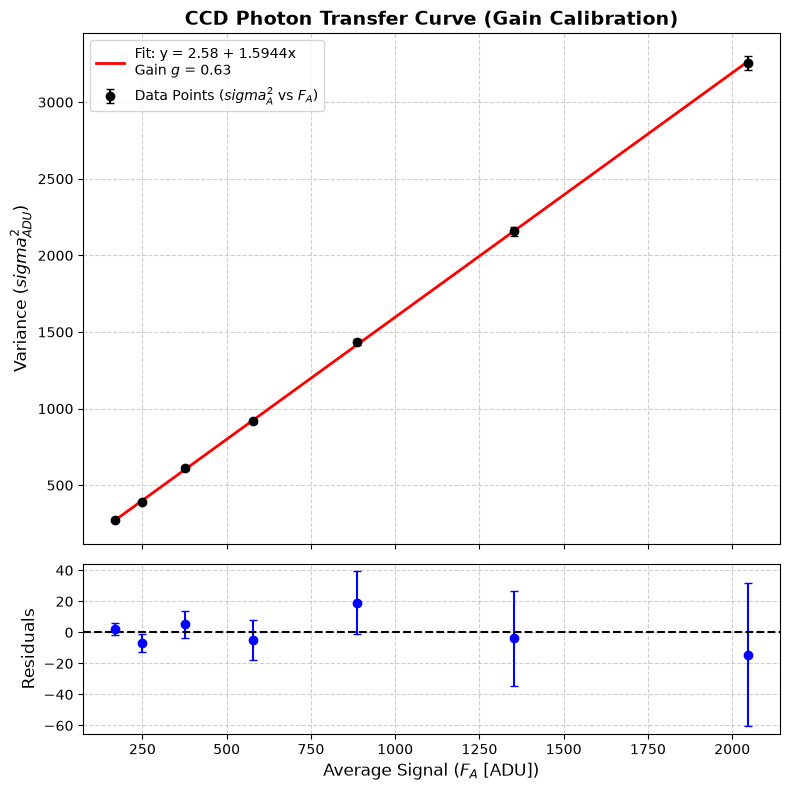

In [8]:
#Gain Calculation
twilight_ind_A = [0, 15, 30, 45, 60, 75, 90]
twilight_ind_B = [1, 16, 31, 46, 61, 76, 91]

twilight_data_A = []
for file_num, file in enumerate(twilight_flats):
    if file_num in twilight_ind_A:
        with fits.open(file) as foo:
            raw_data = foo[0].data
            real_data = count_conversion(raw_data)
            bias_subtracted_flat = real_data - mean_bias
            twilight_data_A.append(bias_subtracted_flat)
twilight_flats_A = np.array(twilight_data_A)

twilight_data_B = []
for file_num, file in enumerate(twilight_flats):
    if file_num in twilight_ind_B:
        with fits.open(file) as foo:
            raw_data = foo[0].data
            real_data = count_conversion(raw_data)
            bias_subtracted_flat = real_data - mean_bias
            twilight_data_B.append(bias_subtracted_flat)
twilight_flats_B = np.array(twilight_data_B)

signals = []
variances = []
for img_num, img_A in enumerate(twilight_flats_A):
    sub_A = img_A[0:100, 0:100]
    sub_B = twilight_flats_B[img_num][0:100, 0:100]

    FA = np.mean(sub_A)
    FB = np.mean(sub_B)

    r = FA / FB
    diff_image = sub_A - (r * sub_B)

    sigma2_D = np.var(diff_image, ddof=1)
    sigma2_A = sigma2_D / 2.0

    signals.append(FA)
    variances.append(sigma2_A)

signals = np.array(signals)
variances = np.array(variances)

N_pixels = 100 * 100
y_uncert = variances * np.sqrt(2.0 / (N_pixels - 1))

y0, y0_err, slope_w, slope_err, residuals, chi2_red = least_squares(signals, variances, y_uncert)
gain = 1 / slope_w
gain_err = (slope_err / slope_w ** 2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True, 
                               gridspec_kw={'height_ratios': [3, 1]})

ax1.errorbar(signals, variances, yerr=y_uncert, fmt='ko', capsize=3, label='Data Points ($sigma^2_A$ vs $F_A$)')

x_fit = np.linspace(np.min(signals), np.max(signals), 100)
y_fit = y0 + slope_w * x_fit
ax1.plot(x_fit, y_fit, 'r-', lw=2, label=f'Fit: y = {y0:.2f} + {slope_w:.4f}x\nGain $g$ = {gain:.2f}')

ax1.set_ylabel('Variance ($sigma^2_{ADU}$)', fontsize=12)
ax1.set_title('CCD Photon Transfer Curve (Gain Calibration)', fontsize=14, fontweight='bold')
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.errorbar(signals, residuals, yerr=y_uncert, fmt='bo', capsize=3)
ax2.axhline(0, color='black', linestyle='--', lw=1.5)
ax2.set_xlabel('Average Signal ($F_A$ [ADU])', fontsize=12)
ax2.set_ylabel('Residuals', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("Gain_LSF.png")

print(f"--- Least Squares Fit Results ---")
print(f"Intercept (Read Noise term): {y0:.4f} ± {y0_err:.4f}")
print(f"Slope: {slope_w:.6f} ± {slope_err:.6f} ADU/e-")
print(f"Calculated Gain (g): {gain:.4f} ± {gain_err:.4f} e-/ADU")
print(f"Reduced Chi-squared (chi2_red): {chi2_red:.4f}")

In [9]:
#Load and reduce star data
eps_del = load_files(eps_del,) #30 Seconds, 2026-09-22T05:34:53
HD199280 = load_files(HD199280) #60 Seconds, 2026-09-22T06:30:37
HD199280_2130 = load_files(HD199280_2130) #60 Seconds, 2026-09-22T03:39:47

HD189658 = load_files(HD189658) #120 Seconds, 2026-09-22T05:06:42
HD198727 = load_files(HD198727) #120 Seconds, 2026-09-22T04:40:28
SA113267 = load_files(SA113267) #120 Seconds, 2026-09-22T06:58:14
SA1111496 = load_files(SA1111496) #120 Seconds, 2026-09-22T06:05:31

vega1 = load_files(vega1) #5 Seconds, 2026-09-22T06:18:00
vega2 = load_files(vega2) #5 Seconds, 2026-09-22T03:23:10

eps_del_sample = reduce_data(eps_del[0], mean_dark_30s)
HD199280_sample = reduce_data(HD199280[0], mean_dark_60s)
HD199280_2130_sample = reduce_data(HD199280_2130[0], mean_dark_60s)
HD189658_sample = reduce_data(HD189658[2], mean_dark_120s)
HD198727_sample = reduce_data(HD198727[0], mean_dark_120s)
SA113267_sample = reduce_data(SA113267[6], mean_dark_120s)
SA1111496_sample = reduce_data(SA1111496[0], mean_dark_120s)
vega1_sample = reduce_data(vega1[2], mean_dark_5s)
vega2_sample = reduce_data(vega2[2], mean_dark_5s)

Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 11
Shape of image stack: (11, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)
Number of files found: 10
Shape of image stack: (10, 3522, 4656)


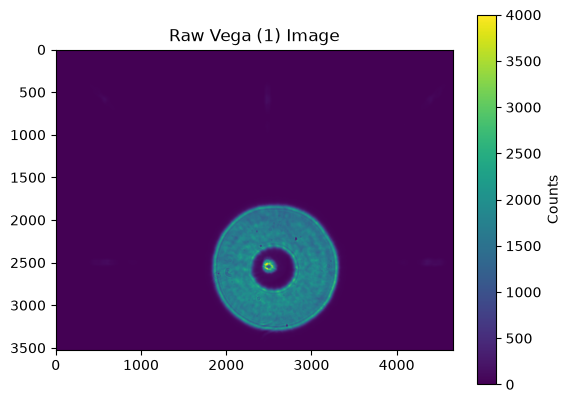

In [10]:
plt.imshow(vega1_sample, vmin=0, vmax=4000)
plt.colorbar(label="Counts")
plt.title("Raw Vega (1) Image")
plt.savefig("Vega1_raw.png")

Total Flux: 496214812.97 counts


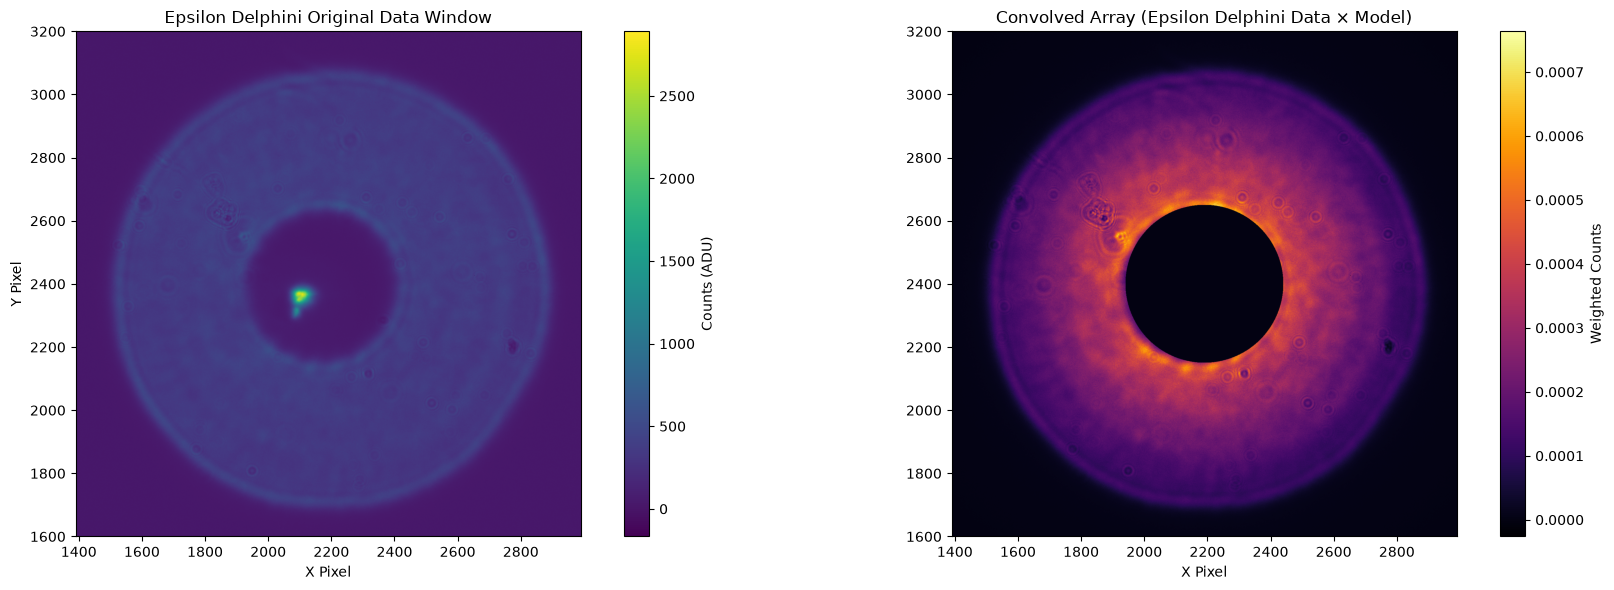

In [11]:
#Eps_del data --- Centroid: (2200,2400), Inner R:250 Outer R: 700
cx, cy = 2190, 2400
inner_radius = 250       
window_size = 800       
w_x, w_y = 400.0, 400.0  

model_eps, convolved_patch, total_star_flux = phot(
    data=eps_del_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Flux: {total_star_flux:.2f} counts")
eps_del_flux = total_star_flux

plot_phot(eps_del_sample, cx, cy, window_size, model_eps, convolved_patch, "Epsilon Delphini")

Total Flux: 183656746.75 counts


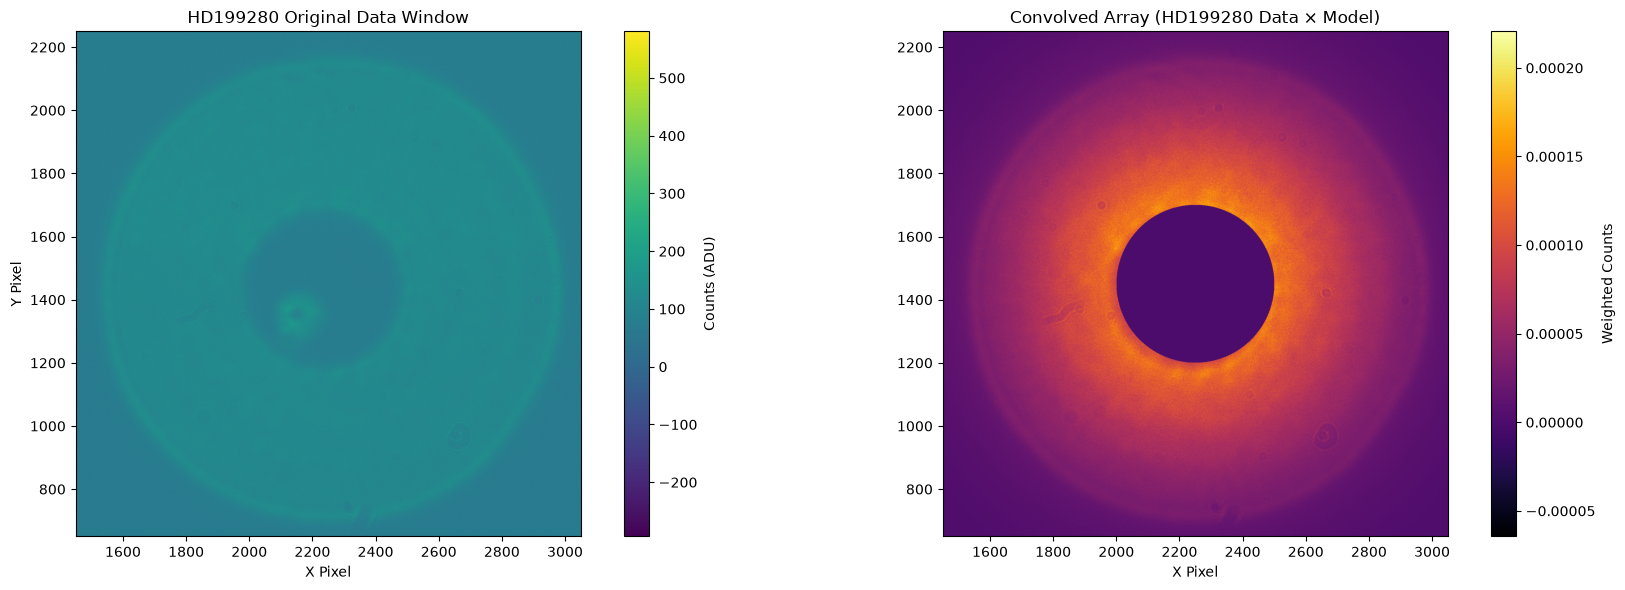

In [12]:
#HD199280 data --- Centroid: (2250,1400), Inner R:250 Outer R: 750
cx, cy = 2250,1450  

model_HD199280, convolved_patch, total_star_flux = phot(
    data=HD199280_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Flux: {total_star_flux:.2f} counts")
HD199280_flux = total_star_flux

plot_phot(HD199280_sample, cx, cy, window_size, model_HD199280, convolved_patch, "HD199280")

Total Flux: 179093709.05 counts


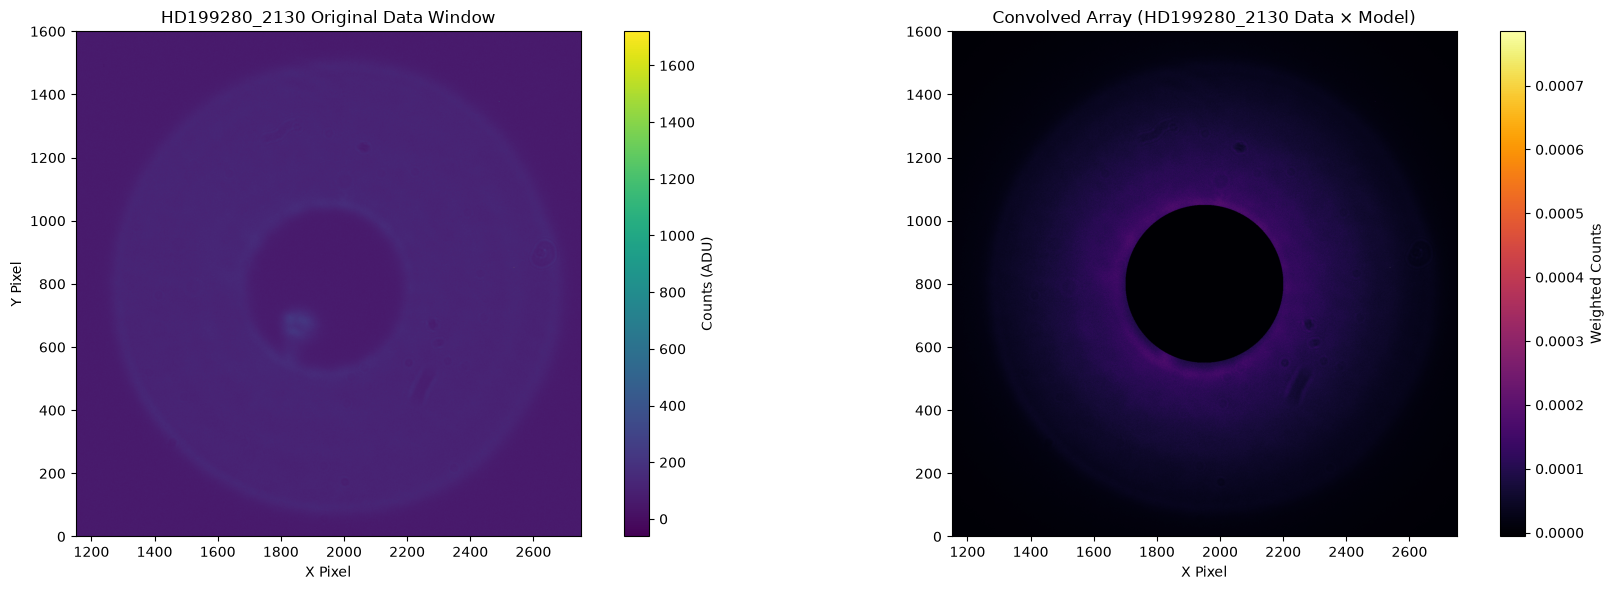

In [13]:
#HD199280_2130 data --- Centroid: (1900,800), Inner R:250 Outer R:700
cx, cy = 1950,800  

model_HD199280_2130, convolved_patch, total_star_flux = phot(
    data=HD199280_2130_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Flux: {total_star_flux:.2f} counts")
HD199280_2130_flux = total_star_flux

plot_phot(HD199280_2130_sample, cx, cy, window_size, model_HD199280_2130, convolved_patch, "HD199280_2130")

Total Flux: 189248089.63 counts


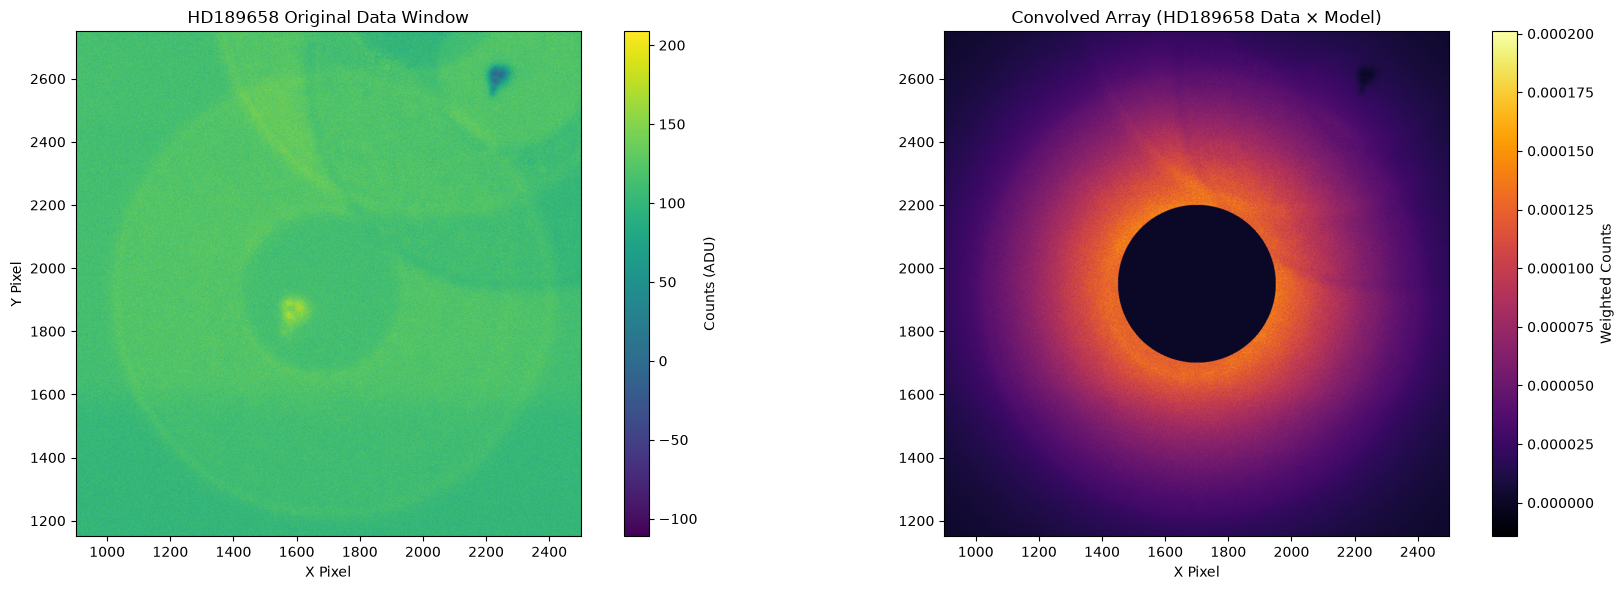

In [14]:
#HD189658 data --- Centroid: (1700,1900), Inner R:250 Outer R:700
cx, cy = 1700,1950 

model_HD189658, convolved_patch, total_star_flux = phot(
    data=HD189658_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Flux: {total_star_flux:.2f} counts")
HD189658_flux = total_star_flux

plot_phot(HD189658_sample, cx, cy, window_size, model_HD189658, convolved_patch, "HD189658")

Total Flux: 162616612.87 counts


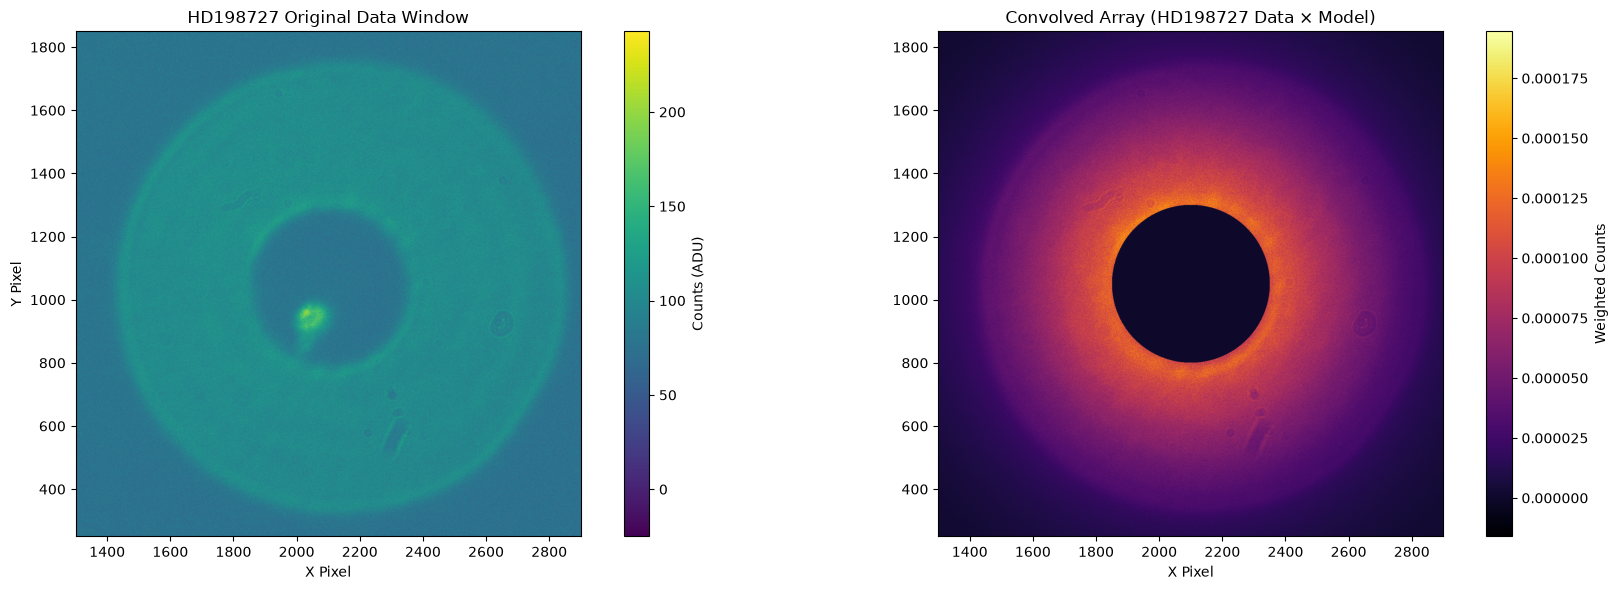

In [15]:
#HD198727 data --- Centroid: (2100,1050), Inner R:250 Outer R:700
cx, cy = 2100,1050  

model_HD198727, convolved_patch, total_star_flux = phot(
    data=HD198727_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Flux: {total_star_flux:.2f} counts")
HD198727_flux = total_star_flux

plot_phot(HD198727_sample, cx, cy, window_size, model_HD198727, convolved_patch, "HD198727")

Total Flux: 275465270.32 counts


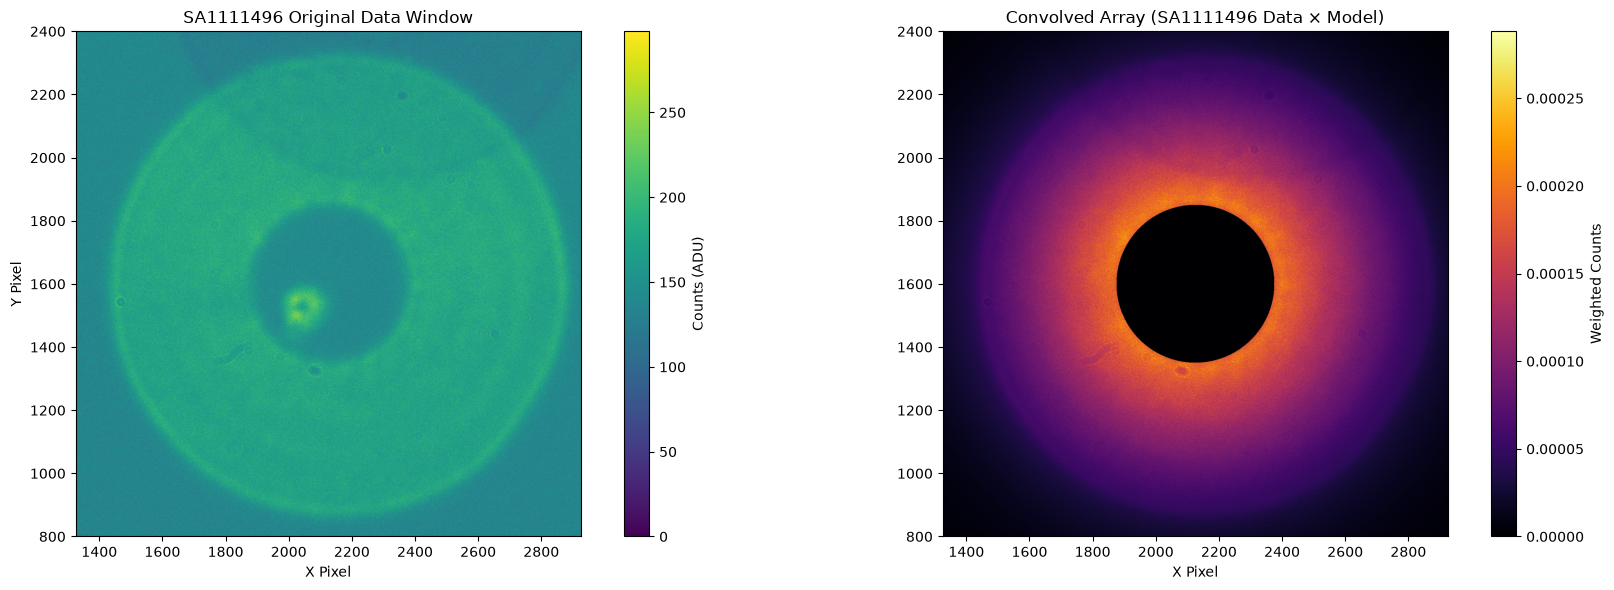

In [16]:
#SA1111496 data --- Centroid: (2125,1600), Inner R:250 Outer R:700
cx, cy = 2125,1600  

model_SA1111496, convolved_patch, total_star_flux = phot(
    data=SA1111496_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Flux: {total_star_flux:.2f} counts")
SA1111496_flux = total_star_flux

plot_phot(SA1111496_sample, cx, cy, window_size, model_SA1111496, convolved_patch, "SA1111496")

Total Flux: 228638644.11 counts


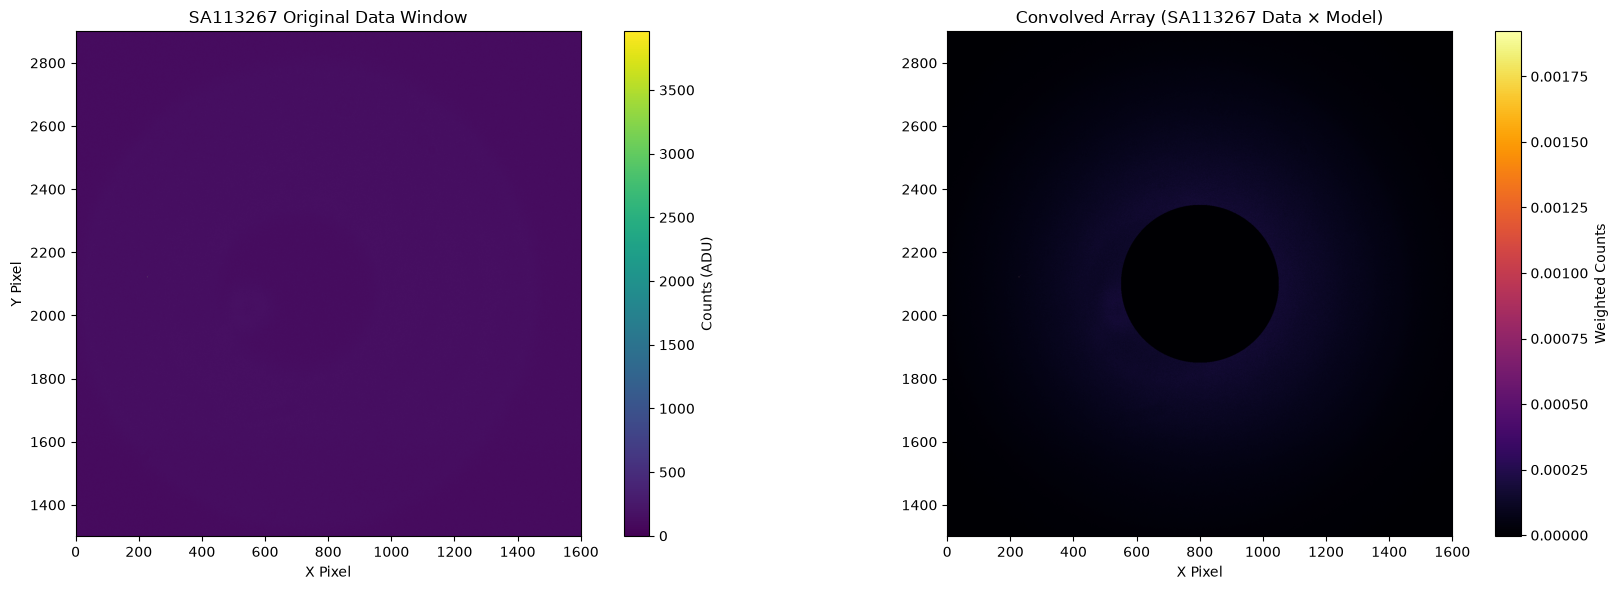

In [17]:
#SA113267 data --- Centroid: (700,2100), Inner R:250 Outer R:700
cx, cy = 800,2100  

model_SA113267, convolved_patch, total_star_flux = phot(
    data=SA113267_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Flux: {total_star_flux:.2f} counts")
SA113267_flux = total_star_flux

plot_phot(SA113267_sample, cx, cy, window_size, model_SA113267, convolved_patch, "SA113267")

Total Flux: 2512760970.53 counts


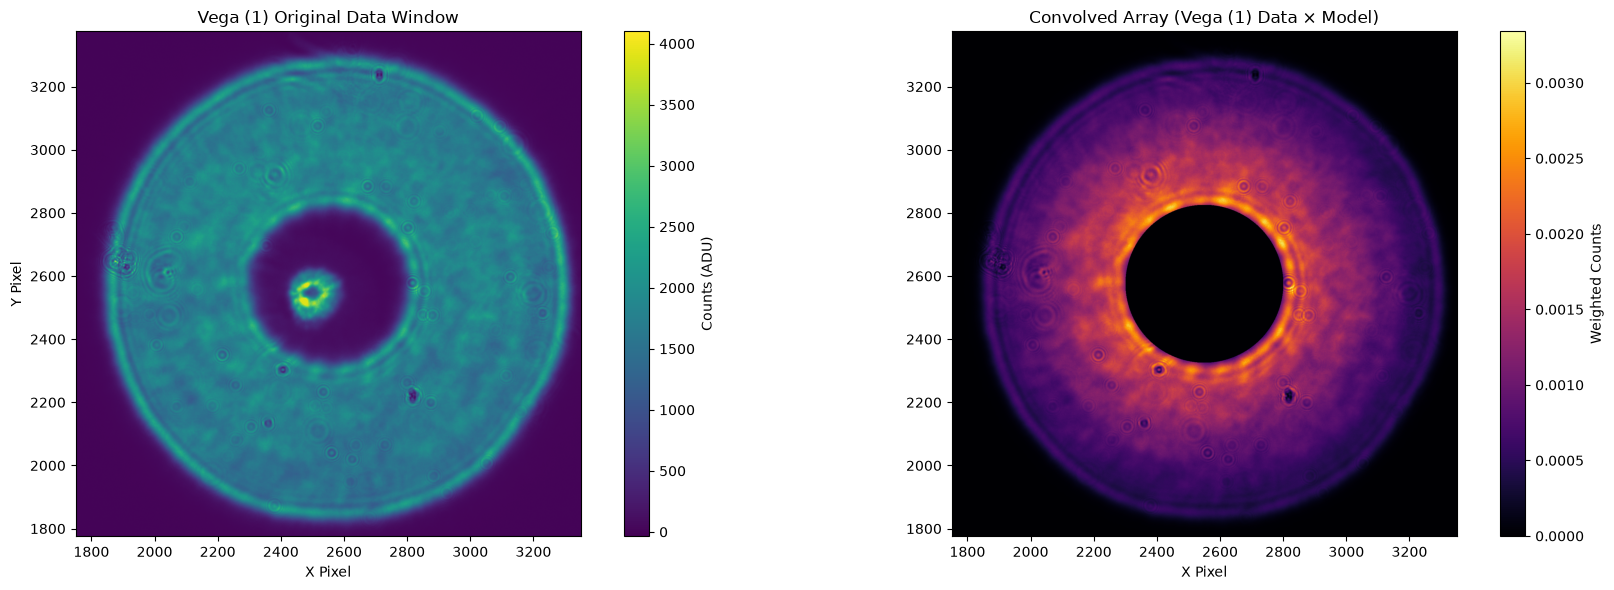

In [18]:
#vega1 data --- Centroid: (2550,2550), Inner R:250 Outer R:700
cx, cy = 2550,2575  

model_vega1, convolved_patch, total_star_flux = phot(
    data=vega1_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Flux: {total_star_flux:.2f} counts")
vega1_flux = total_star_flux

plot_phot(vega1_sample, cx, cy, window_size, model_vega1, convolved_patch, "Vega (1)")

Total Instrumental Flux: 3095777716.71 counts


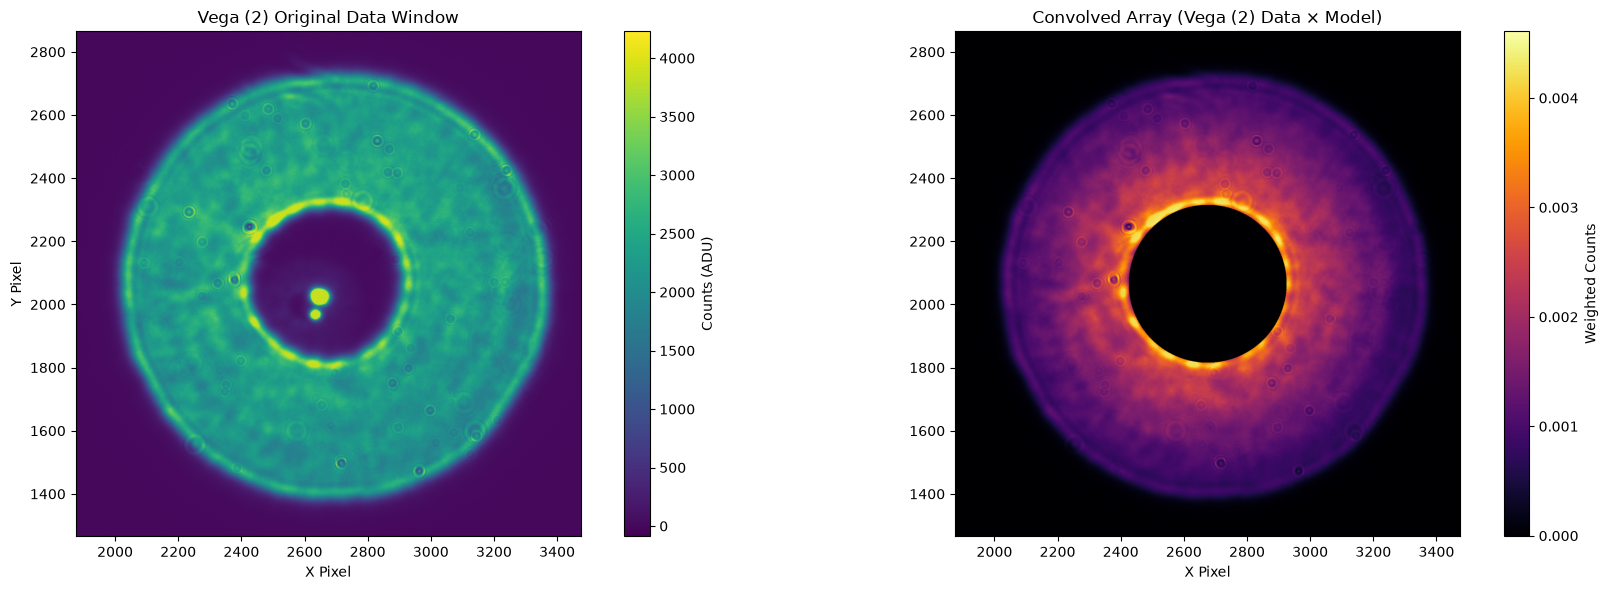

In [19]:
#vega2 data --- Centroid: (2700,2100), Inner R:250 Outer R:700
cx, cy = 2675,2065  

model_vega2, convolved_patch, total_star_flux = phot(
    data=vega2_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Instrumental Flux: {total_star_flux:.2f} counts")
vega2_flux = total_star_flux

plot_phot(vega2_sample, cx, cy, window_size, model_vega2, convolved_patch, "Vega (2)")

Total Sky Flux: 125942232.66 counts


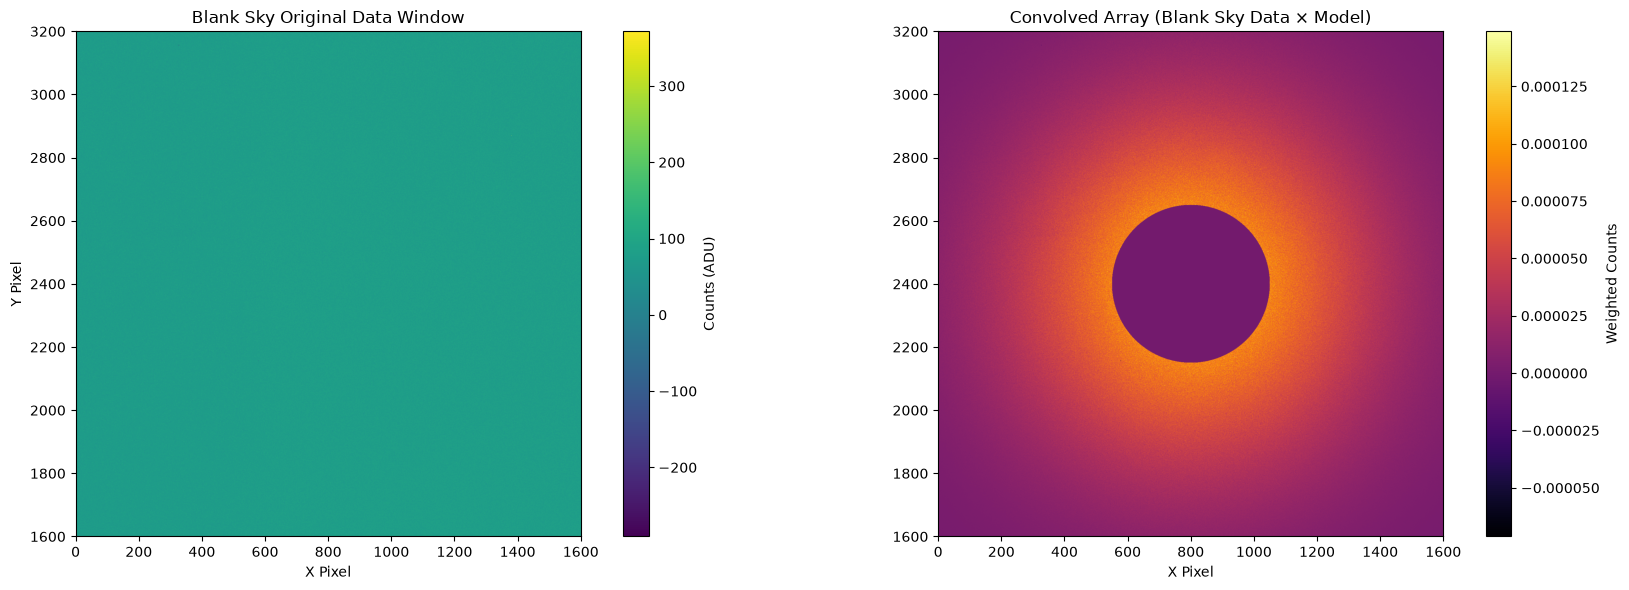

In [20]:
#Blank sky convolvement for error subtraction
cx, cy = 800,2400  

model_grid, convolved_patch, total_star_flux = phot(
    data=HD198727_sample, 
    centroid_x=cx, 
    centroid_y=cy, 
    width_x=w_x, 
    width_y=w_y, 
    window=window_size, 
    inner_rad=inner_radius
)
print(f"Total Sky Flux: {total_star_flux:.2f} counts")
sky_flux = total_star_flux

plot_phot(HD198727_sample, cx, cy, window_size, model_grid, convolved_patch, "Blank Sky")

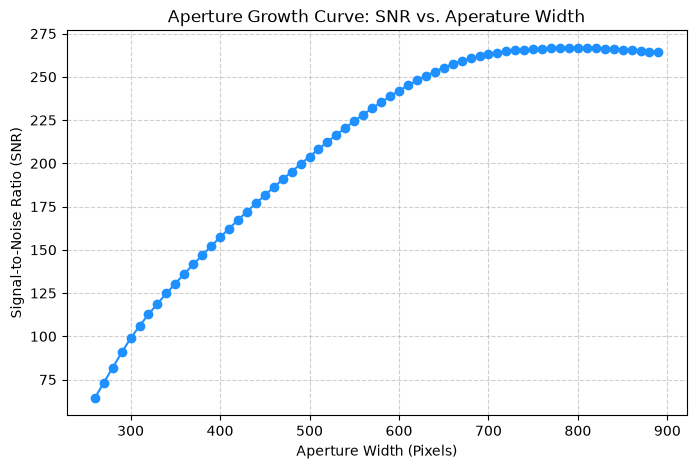

In [21]:
#vega1 data --- Centroid: (2550,2550), Inner R:250 Outer R:700
cx, cy = 2550, 2550
inner_radius = 250
w_x, w_y = 350.0, 350.0

window_sizes = np.arange(260, 900, 10)
flux_list = []
snr_list = []
aperature_width_list = []

#Instrument constants
g = 0.6272        
N_R = 2.1213      

snr_list = []
for window in window_sizes:
    model, psf_convolve, psf_flux = phot(
        vega2_sample, 
        2700, 
        2100, 
        window * 0.5, 
        window * 0.5, 
        window, 
        250
    )    
    n_eff = 1.0 / np.sum(model**2)
    variance = (gain * psf_flux) + (n_eff * gain * sky_flux) + (n_eff * (read_noise**2))
    snr = psf_flux / np.sqrt(variance)
    
    flux_list.append(psf_flux)
    snr_list.append(snr)
    aperature_width_list.append(window)

plt.figure(figsize=(8, 5))
plt.plot(aperature_width_list, snr_list, marker='o', color='dodgerblue', linestyle='-')
plt.title("Aperture Growth Curve: SNR vs. Aperature Width")
plt.xlabel("Aperture Width (Pixels)")
plt.ylabel("Signal-to-Noise Ratio (SNR)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("Aperature_plot")

In [22]:
#Calculate Instrumental Magnetudes
eps_del_mag = calc_mag(eps_del_flux, 30, sky_flux)
print(f"Eps Del Magnitude: {eps_del_mag:.4f}")
HD199280_mag = calc_mag(HD199280_flux, 60, sky_flux)
print(f"HD199280 Magnitude: {HD199280_mag:.4f}")
HD199280_2130_mag = calc_mag(HD199280_2130_flux, 60, sky_flux)
print(f"HD199280_2130 Magnitude: {HD199280_2130_mag:.4f}")

HD189658_mag = calc_mag(HD189658_flux, 120, sky_flux)
print(f"HD189658 Magnitude: {HD189658_mag:.4f}")
HD198727_mag = calc_mag(HD198727_flux, 120, sky_flux)
print(f"HD198727 Magnitude: {HD198727_mag:.4f}")
SA113267_mag = calc_mag(SA113267_flux, 120, sky_flux)
print(f"SA113267 Magnitude: {SA113267_mag:.4f}")
SA1111496_mag = calc_mag(SA1111496_flux, 120, sky_flux)
print(f"SA1111496 Magnitude: {SA1111496_mag:.4f}")

vega1_mag = calc_mag(vega1_flux, 5, sky_flux)
print(f"Vega1 Magnitude: {vega1_mag:.4f}")
vega2_mag = calc_mag(vega2_flux, 5, sky_flux)
print(f"Vega2 Magnitude: {vega2_mag:.4f}")

Eps Del Magnitude: -17.7285
HD199280 Magnitude: -14.9578
HD199280_2130 Magnitude: -14.8684
HD189658 Magnitude: -14.3057
HD198727 Magnitude: -13.7130
SA113267 Magnitude: -14.8309
SA1111496 Magnitude: -15.2388
Vega1 Magnitude: -21.6971
Vega2 Magnitude: -21.9344


In [23]:
#Calculate offset
C1 = 0.026 - vega1_mag
C2 = 0.026 - vega2_mag
print(f"C1: {C1:.4f}")
print(f"C2: {C2:.4f}")

airmass1 = find_airmass('2026-09-22T06:18:00', 'Vega')
airmass2 = find_airmass('2026-09-22T03:23:10', 'Vega')

print(f"Observation Time (UT): 2026-09-22T06:18:00")
print(f"Target: Vega")
print(f"Calculated Airmass (sec z1): {airmass1:.4f}")

print(f"Observation Time (UT): 2026-09-22T03:23:10")
print(f"Target: Vega")
print(f"Calculated Airmass (sec z2): {airmass2:.4f}")

k = (C1 - C2) / (airmass1 - airmass2)
ZP = C1 - k*airmass1
print(f"Extinction Coefficiant: {k:.4f}")
print(f"Zero point: {ZP:.4f}")

C1: 21.7231
C2: 21.9604
Observation Time (UT): 2026-09-22T06:18:00
Target: Vega
Calculated Airmass (sec z1): 1.4161
Observation Time (UT): 2026-09-22T03:23:10
Target: Vega
Calculated Airmass (sec z2): 1.0384
Extinction Coefficiant: -0.6281
Zero point: 22.6126


In [24]:
#Correct Magnitudes
eps_del_real_mag, eps_del_airmass = correct_magnitude(eps_del_mag, "Epsilon Delphini","2026-09-22T05:34:53")
HD199280_real_mag, HD199280_airmass = correct_magnitude(HD199280_mag, "HD199280", "2026-09-22T06:30:37")
HD199280_2130_real_mag, HD199280_2130_airmass = correct_magnitude(HD199280_2130_mag, "HD199280-2130", "2026-09-22T03:39:47")
HD189658_real_mag, HD189658_airmass = correct_magnitude(HD189658_mag, "HD189658", "2026-09-22T05:06:42")
HD198727_real_mag, HD198727_airmass = correct_magnitude(HD198727_mag, "HD198727", "2026-09-22T04:40:28")
SA113267_real_mag, SA113267_airmass = correct_magnitude(SA113267_mag, "SA113267", "2026-09-22T06:58:14")
SA1111496_real_mag, SA1111496_airmass = correct_magnitude(SA1111496_mag, "SA1111496", "2026-09-22T06:05:31")
vega1_real_mag, vega1_airmass = correct_magnitude(vega1_mag, "Vega", "2026-09-22T06:18:00")
vega2_real_mag, vega2_airmass = correct_magnitude(vega2_mag, "Vega", "2026-09-22T03:23:10")

Target: Epsilon Delphini
Airmass: 1.307657575852012
Magnitude: 4.062759522771414
Target: HD199280
Airmass: 1.835550125101962
Magnitude: 6.501866264618171
Target: HD199280-2130
Airmass: 1.6072252898016093
Magnitude: 6.734697137012535
Target: HD189658
Airmass: 1.2590467983978448
Magnitude: 7.516135179827387
Target: HD198727
Airmass: 1.1199551068404172
Magnitude: 8.19619886436736
Target: SA113267
Airmass: 1.6102174429937295
Magnitude: 6.7702929708241655
Target: SA1111496
Airmass: 1.9977594627500588
Magnitude: 6.11900290760134
Target: Vega
Airmass: 1.41614140579784
Magnitude: 0.026000000000001022
Target: Vega
Airmass: 1.0383522163050638
Magnitude: 0.026000000000001022


In [25]:
#Uncertanty Calculations

#Instrument constants
g = 0.6272        
N_R = 2.1213 

n_eff = 1.0 / np.sum(model_vega1**2)
variance = (gain * vega1_flux) + (n_eff * gain * sky_flux) + (n_eff * (read_noise**2))
SNR = psf_flux / np.sqrt(variance)
C1_uncert = 1 / SNR
C2_uncert = 1 / SNR
k_uncert = np.sqrt(C1_uncert**2 + C2_uncert**2) / np.abs(vega1_airmass - vega2_airmass)
ZP_uncert = np.sqrt(C1_uncert**2 + (vega1_airmass * k_uncert)**2)
print("---Uncertanties---")
print(f"C1 = {C1_uncert}")
print(f"C2 = {C2_uncert}")
print(f"k = {k_uncert}")
print(f"ZP = {ZP_uncert}")
print("---Stars---")

eps_del_uncert = calc_uncert(model_eps, eps_del_flux, eps_del_real_mag, eps_del_airmass)
print(f"Eps_del_uncert: {eps_del_uncert}")
HD199280_uncert = calc_uncert(model_HD199280, HD199280_flux, HD199280_real_mag, HD199280_airmass)
print(f"HD199280_uncert: {HD199280_uncert}")
HD199280_2130_uncert = calc_uncert(model_HD199280_2130, HD199280_2130_flux, HD199280_2130_real_mag, HD199280_2130_airmass)
print(f"HD199280_2130_uncert: {HD199280_2130_uncert}")
HD189658_uncert = calc_uncert(model_HD189658, HD189658_flux, HD189658_real_mag, HD189658_airmass)
print(f"HD189658_uncert: {HD189658_uncert}")
HD198727_uncert = calc_uncert(model_HD198727, HD198727_flux, HD198727_real_mag, HD198727_airmass)
print(f"HD198727_uncert: {HD198727_uncert}")
SA113267_uncert = calc_uncert(model_SA113267, SA113267_flux, SA113267_real_mag, SA113267_airmass)
print(f"SA113267_uncert: {SA113267_uncert}")
SA1111496_unct = calc_uncert(model_SA1111496, SA1111496_flux, SA1111496_real_mag, SA1111496_airmass)
print(f"SA1111496_uncert: {SA1111496_unct}")
vega1_uncert = calc_uncert(model_vega1, vega1_flux, vega1_real_mag, vega1_airmass)
print(f"vega1_uncert: {vega1_uncert}")
vega2_uncert = calc_uncert(model_vega2, vega2_flux, vega2_real_mag, vega2_airmass)
print(f"vega2_uncert: {vega2_uncert}")

---Uncertanties---
C1 = 0.003389003329877057
C2 = 0.003389003329877057
k = 0.012686372732037524
ZP = 0.018282550094685556
---Stars---
Eps_del_uncert: 0.09590101349191531
HD199280_uncert: 0.40178722536157324
HD199280_2130_uncert: 0.4264986469378215
HD189658_uncert: 0.45017179765868204
HD198727_uncert: 0.5709364141687482
SA113267_uncert: 0.33627041909659483
SA1111496_uncert: 0.25335287824975405
vega1_uncert: 0.025632628580754945
vega2_uncert: 0.022534120368679935


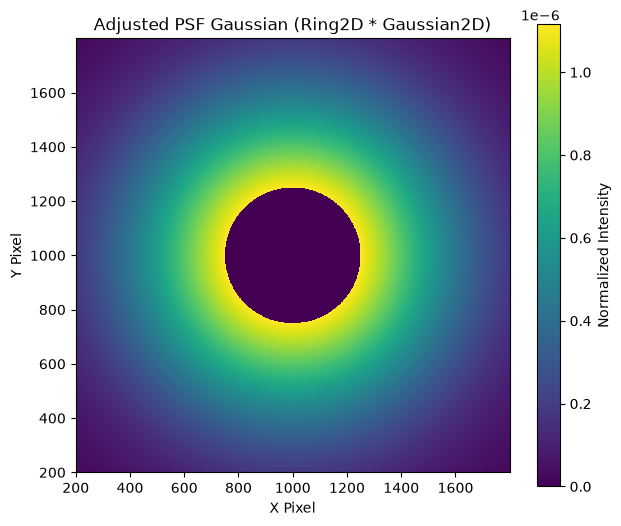

In [26]:
center = (1000, 1000)   # Example centroid (x, y)
width_x = 400          # Gaussian width in x
width_y = 400          # Gaussian width in y
window = 800          # Window size
inner_rad = 250       # Inner radius of the ring

xx, yy, normalized = psf(center, width_x, width_y, window, inner_rad)

plt.figure(figsize=(7, 6))
plt.pcolormesh(xx, yy, normalized, shading='auto', cmap='viridis')

plt.colorbar(label='Normalized Intensity')
plt.title('Adjusted PSF Gaussian (Ring2D * Gaussian2D)')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel')
plt.gca().set_aspect('equal') # Keeps the pixels square
plt.savefig("PSF_plot.png")

In [28]:
eps_del_uncert = calc_uncert(model_eps, eps_del_flux, eps_del_real_mag, eps_del_airmass, True)
print(f"Eps_del_uncert: {eps_del_uncert}")

SNR: 43.841624851553746
inst_uncert: 0.09266899975828405
air_uncert: 0.016589431413131253
Eps_del_uncert: 0.09590101349191531
